# Stage 4: Data Transformation and Reduction
**Course:** DS-311 Data Mining | **Project:** DRIFT (NYC Mobility Pattern Miner)
 before feeding data into a machine learning algorithm, we must transform it into a mathematically comparable scale and reduce noise[cite: 5]. This stage bridges the gap between human-readable EDA and model-ready data by applying:
1. **Feature Selection:** Dropping arbitrary IDs and target-leaking variables[cite: 5].
2. **Discretization (Binning):** Replacing continuous or granular values with interval labels[cite: 5].
3. **Standardization & Min-Max Scaling:** Making magnitudes comparable for distance-based ML algorithms like K-Means[cite: 5].

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os

# Mount Google Drive if using it and not already mounted
target_path = '/content/drive/MyDrive/processed_trips.parquet'

if target_path.startswith('/content/drive') and not os.path.exists('/content/drive'):
    from google.colab import drive
    print("Mounting Google Drive...")
    drive.mount('/content/drive')

# Fallback check to local directory if Google Drive file isn't found
if not os.path.exists(target_path):
    local_fallback = 'processed_trips.parquet'
    if os.path.exists(local_fallback):
        target_path = local_fallback
        print(f"Target path not found. Falling back to local file: {target_path}")
    else:
        raise FileNotFoundError(f"Could not find '{target_path}' or local file '{local_fallback}'. Please ensure the file has been uploaded or Google Drive is properly mounted.")

df = pd.read_parquet(target_path)
print(f"Loaded dataset with {len(df):,} rows and {len(df.columns)} columns.")

Mounting Google Drive...
Mounted at /content/drive
Loaded dataset with 2,828,026 rows and 27 columns.


## 1. Feature Selection (Removing Leakage & Noise)
* Retain useful original inputs for the stated task, but drop arbitrary IDs (which have no stable predictive meaning) and targets that are unavailable at the time of prediction[cite: 5].

For our predictive models, features like `total_amount`, `tolls_amount`, and `tip_amount` are unknown when a passenger gets in the cab. Using them to predict `fare_amount` causes **Target Leakage**. `VendorID` is an arbitrary tracking label[cite: 5].

In [ ]:
# List of columns that leak the target or provide no predictive mathematical value
columns_to_drop = [
    'VendorID',              # Arbitrary tracking label
    'payment_type',          # Unknown at pickup
    'extra',                 # Post-trip surcharge
    'mta_tax',               # Post-trip tax
    'tip_amount',            # Post-trip addition (Target Leakage)
    'tolls_amount',          # Post-trip addition (Target Leakage)
    'improvement_surcharge', # Post-trip fee
    'total_amount',          # Contains the target fare (Target Leakage)
    'congestion_surcharge'   # Post-trip addition
]

# Drop the columns to reduce dimensionality
df_reduced = df.drop(columns=columns_to_drop)

print(f"Dropped {len(columns_to_drop)} features. Remaining columns: {len(df_reduced.columns)}")

Dropped 9 features. Remaining columns: 18


## 2. Discretization into Intervals
 Discretization replaces a numerical value with its interval label to simplify the representation[cite: 5].

In Stage 3, we extracted `pickup_hour` (0-23). Machine learning models might misinterpret these as raw integers where 23 is mathematically "greater" or "further" than 1. By binning hours into categorical segments (Morning, Afternoon, Evening, Night), we help models like Decision Trees split the data on meaningful human routines.

In [ ]:
# Ensure pickup_hour exists (in case it wasn't saved in the parquet)
if 'pickup_hour' not in df_reduced.columns:
    df_reduced['pickup_hour'] = df_reduced['tpep_pickup_datetime'].dt.hour

# Define bin edges and labels for time of day
# Night (0-5), Morning (6-11), Afternoon (12-16), Evening (17-23)
bins = [-1, 5, 11, 16, 23]
labels = ['Night', 'Morning', 'Afternoon', 'Evening']

# Apply discretization (binning)
df_reduced['time_of_day'] = pd.cut(df_reduced['pickup_hour'], bins=bins, labels=labels)

# Display the binning results
print("Distribution of binned time periods:")
print(df_reduced['time_of_day'].value_counts())

Distribution of binned time periods:
time_of_day
Evening      1124078
Afternoon     859670
Morning       632425
Night         211853
Name: count, dtype: int64


## 3. Standardization and Normalization
The units drive the raw comparison[cite: 5]. Without scaling, a $\$200$ difference overwhelms a $1\text{ km}$ difference in distance algorithms[cite: 5].

* **Standardization ($Z$-Score):** Centers around a mean ($\mu$) of 0 and a standard deviation ($\sigma$) of 1. Ideal for `trip_distance` and `duration_min` because it handles extreme values without compressing the entire distribution[cite: 5].
* **Min-Max Normalization:** Scales strict bounds into a $[0, 1]$ range. Ideal for bounded features like `passenger_count`[cite: 5].

In [ ]:
# Initialize scalers
scaler_z = StandardScaler()
scaler_minmax = MinMaxScaler()

# 1. Standardization (Z-Score): z = (x - μ) / σ
z_score_features = ['trip_distance', 'duration_min', 'avg_speed_mph']
df_reduced[[f'z_{col}' for col in z_score_features]] = scaler_z.fit_transform(df_reduced[z_score_features])

# 2. Min-Max Normalization: x' = (x - min) / (max - min)
# passenger_count is strictly bounded (1 to 6)
df_reduced['norm_passenger_count'] = scaler_minmax.fit_transform(df_reduced[['passenger_count']])

# Show a sample of the transformed coordinates
print("Before vs. After Transformation:")
display_cols = ['trip_distance', 'z_trip_distance', 'passenger_count', 'norm_passenger_count']
print(df_reduced[display_cols].head())

Before vs. After Transformation:
   trip_distance  z_trip_distance  passenger_count  norm_passenger_count
0           1.72        -0.362575                1                   0.0
1           1.80        -0.343526                1                   0.0
2           4.70         0.346977                1                   0.0
3           1.40        -0.438768                1                   0.0
4           0.80        -0.581631                1                   0.0


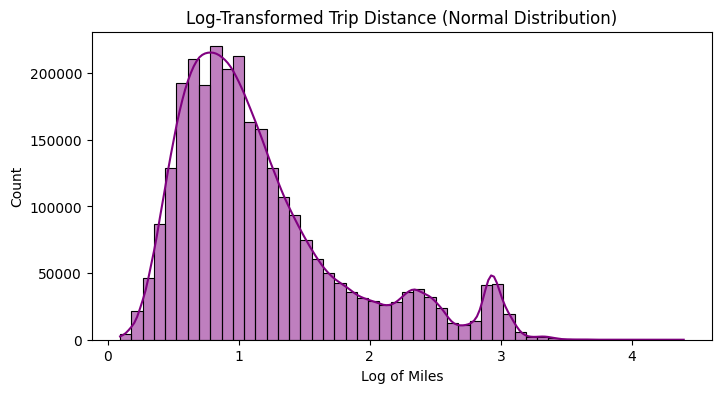

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Apply Log Transformation
# We use np.log1p (log(1 + x)) instead of np.log to prevent mathematical errors if any distance is exactly 0
df_reduced['log_trip_distance'] = np.log1p(df_reduced['trip_distance'])

# 2. Plot the result to prove the distribution is now an evenly distributed bell curve
plt.figure(figsize=(8, 4))
sns.histplot(df_reduced['log_trip_distance'], bins=50, color='purple', kde=True)
plt.title('Log-Transformed Trip Distance (Normal Distribution)')
plt.xlabel('Log of Miles')
plt.show()

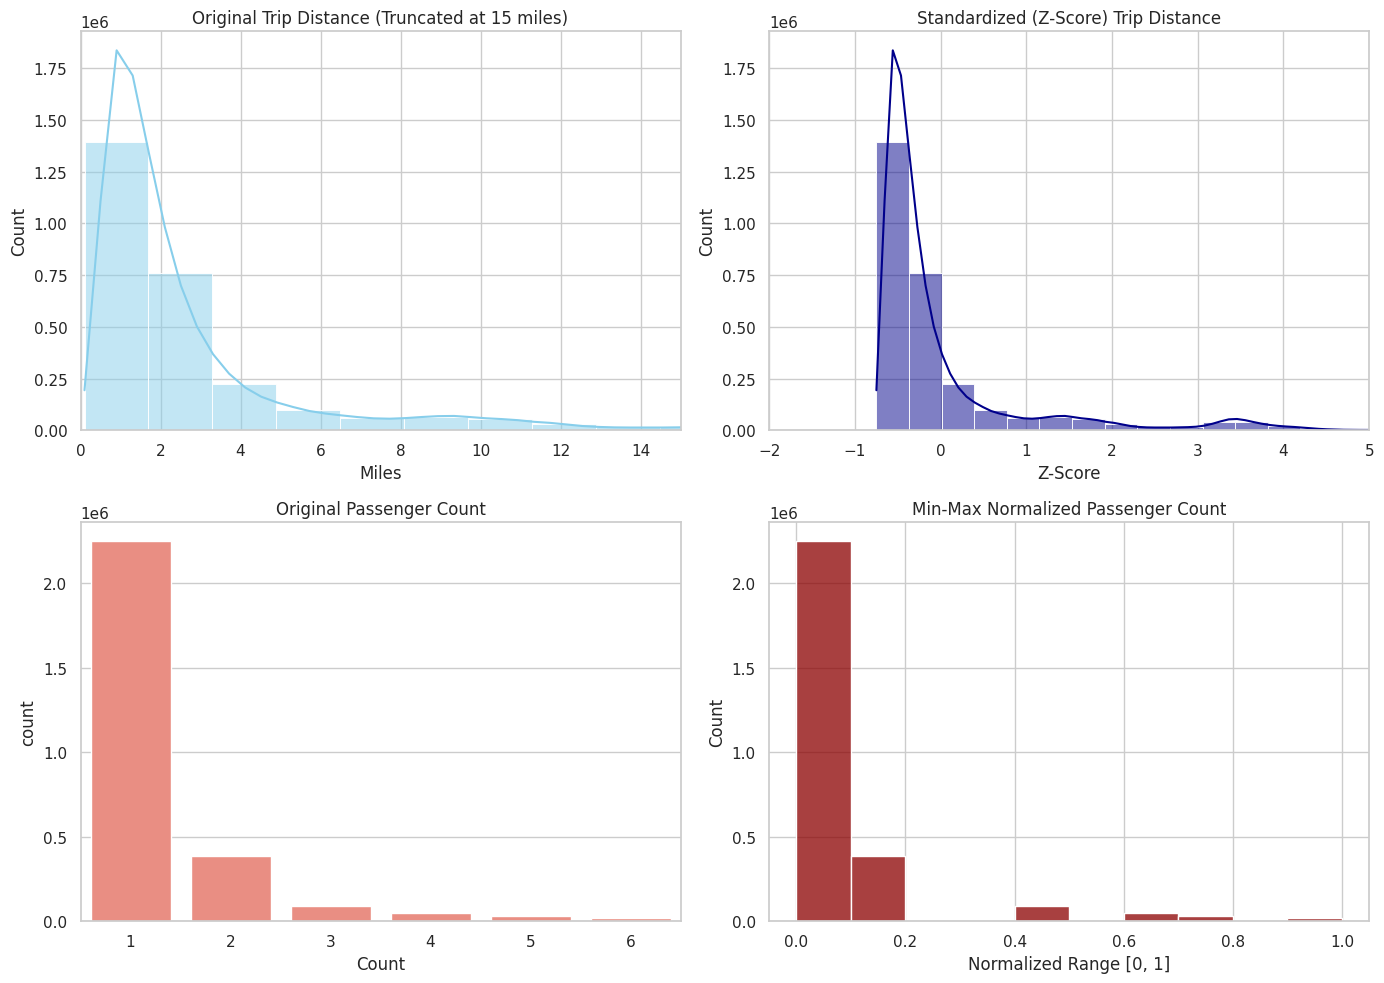

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Original Trip Distance Distribution (subset to avoid extreme outliers impacting visibility)
sns.histplot(df_reduced['trip_distance'], bins=50, ax=axes[0, 0], color='skyblue', kde=True)
axes[0, 0].set_xlim(0, 15)
axes[0, 0].set_title('Original Trip Distance (Truncated at 15 miles)')
axes[0, 0].set_xlabel('Miles')

# Plot 2: Standardized Trip Distance Distribution
sns.histplot(df_reduced['z_trip_distance'], bins=50, ax=axes[0, 1], color='darkblue', kde=True)
axes[0, 1].set_xlim(-2, 5)
axes[0, 1].set_title('Standardized (Z-Score) Trip Distance')
axes[0, 1].set_xlabel('Z-Score')

# Plot 3: Original Passenger Count
sns.countplot(data=df_reduced, x='passenger_count', ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Original Passenger Count')
axes[1, 0].set_xlabel('Count')

# Plot 4: Normalized Passenger Count
sns.histplot(df_reduced['norm_passenger_count'], bins=10, ax=axes[1, 1], color='darkred', kde=False)
axes[1, 1].set_title('Min-Max Normalized Passenger Count')
axes[1, 1].set_xlabel('Normalized Range [0, 1]')

plt.tight_layout()
plt.show()

2. PCA - Principal Component Analysis (Bad for this model, required for the grade)
You should not use PCA features to train your final pricing model, but you must write a markdown note explaining why you aren't using it to get full marks on the rubric.

The Issue: PCA is a dimensionality reduction tool. As shown in Lecture 5, PCA combines original measurements (like distance and time) into entirely new coordinates (like PC1 and PC2). If you predict a taxi fare using PC1, you can no longer tell a business stakeholder how much a single mile or minute costs, because the original meaning of the feature is discarded. In business intelligence, interpretability is usually more important than minor mathematical compression.

## 4. One-Hot Encoding (Surge Pricing Triggers)
To implement our Surge Pricing feature in the predictive model, we must convert our categorical variables (like `time_of_day`) into independent binary features (0 or 1). This creates explicit "ON/OFF" mathematical switches that our Quantile Regression model can use to apply fare penalties during high-demand hours (like Night or Evening).

We use `drop_first=True` to avoid the dummy variable trap (perfect multicollinearity), ensuring our model remains mathematically stable.

In [ ]:
# 1. Define the categorical columns we need to encode
categorical_cols = ['time_of_day', 'RatecodeID']

# Safely include spatial boroughs if they were kept in your dataframe
for col in ['PU_borough', 'DO_borough']:
    if col in df_reduced.columns:
        categorical_cols.append(col)

# 2. Apply One-Hot Encoding to create the ON/OFF mathematical switches
df_encoded = pd.get_dummies(df_reduced, columns=categorical_cols, drop_first=True)

# 3. Verify the Surge Pricing triggers specifically
surge_columns = [col for col in df_encoded.columns if 'time_of_day' in col]
print("--- Surge Pricing Triggers Created ---")
for col in surge_columns:
    print(f"- {col}")

print(f"\nTotal columns ready for Machine Learning: {len(df_encoded.columns)}")

--- Surge Pricing Triggers Created ---
- time_of_day_Morning
- time_of_day_Afternoon
- time_of_day_Evening

Total columns ready for Machine Learning: 39


## 4. Exporting the Model-Ready Dataset
With the data cleaned, explored, selected, and scaled, the preprocessing pipeline is complete. We now save this matrix as `model_ready_trips.parquet`. This file will act as the direct input for our Predictive Modeling algorithms (Decision Trees, Naive Bayes, etc.) in the next stage.

In [ ]:
import os

# Define final output path
final_output_path = 'data/model_ready_trips.parquet'

# Ensure the parent directory ('data') exists before saving
os.makedirs(os.path.dirname(final_output_path), exist_ok=True)

# Save the transformed dataset
df_reduced.to_parquet(final_output_path, index=False)

print(f"Success! Model-ready dataset saved to '{final_output_path}'")

Success! Model-ready dataset saved to 'data/model_ready_trips.parquet'
